# Day 2 — from LSS observables to Fisher forecasts
**Prerequisites:** the Bayesian toy notebook (`01_bayes_toy_example`). **Environment:** `bayes-cfp` (see `README.md`).

In the toy notebook we built a Fisher matrix by hand for a two-parameter model. Here we let **cosmicfishpie** do the same job for Euclid-like observables, but we go **one step at a time** and check each result against what we learnt in the first hour:

1. set up and run a photometric (3×2pt) forecast, and look inside the result;
2. fixed versus marginalised errors, with the `fisher_operations` functions;
3. run the spectroscopic probe, combine probes, and analyse them with the native `fishconsumer` / `fisher_plot_analysis` tools;
4. add a prior;
5. compare with archived Boltzmann-code Fishers and MontePython samples, look at neutrinos, and at a Nautilus run.

The symbolic power-spectrum backend is fast but approximate. These are forecasts of mock observations, not measurements of the real Universe.

Sources: Casas et al., [2303.09451v1](https://arxiv.org/abs/2303.09451v1); Euclid Collaboration, [2405.06047v1](https://arxiv.org/abs/2405.06047v1). File provenance is in `data/manifest.json`.

## 0. Imports and paths

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'
import json
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# cosmicfishpie: the class that computes Fisher matrices ...
from cosmicfishpie.fishermatrix.cosmicfish import FisherMatrix
# ... the container class for a Fisher matrix, and the native tools to work with it
from cosmicfishpie.analysis import fisher_matrix as fm
from cosmicfishpie.analysis import fisher_operations as ops
from cosmicfishpie.analysis import fisher_plot_analysis as cfa
from cosmicfishpie.analysis import fishconsumer as fco

# find the repository root (the folder that contains data/)
ROOT = Path.cwd().resolve()
while not (ROOT / 'data').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / 'data').is_dir(), 'run this notebook from inside the bayes-cosmo-course repository'
DATA = ROOT / 'data'
OUTPUT = ROOT / 'output'
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.size': 12, 'figure.dpi': 110})
# cosmicfishpie sets a global scientific pandas format on import; go back to the default
pd.reset_option('display.float_format')
timings = {}

## 1. A photometric (3×2pt) forecast, step by step
A Fisher forecast needs four ingredients:

| ingredient | what it is | where we put it |
|---|---|---|
| **options** | numerical settings: which power-spectrum backend, how to take derivatives, which survey files | a dictionary `options` |
| **fiducial values** | the "true" parameters at which the derivatives are taken (in Day 1: $H_0=70$, $a=0$) | a dictionary `fiducial` |
| **free parameters** | which parameters we forecast, each with a *relative step size* for the numerical derivative | a dictionary `freepars` |
| **observables** | which probes: `WL` (weak lensing), `GCph` (photometric galaxy clustering), `GCsp` (spectroscopic clustering) | a list |

Remember from Day 1: $F_{ij}=\sum_\ell \dfrac{\partial t}{\partial\theta_i}\,C^{-1}\,\dfrac{\partial t}{\partial\theta_j}$. The model $t(\theta)$ is now the set of angular power spectra $C_\ell$, and the derivatives are taken numerically.

**Step 1: the options.** Every key is a choice we make explicit. Run the cell and read the comments.

In [2]:
options = {
    'feedback': 1,                 # verbosity (this key is required)
    'code': 'symbolic',            # power spectrum backend: 'symbolic' (fast, approximate), 'camb' or 'class' (slow, precise)
    'cosmo_model': 'w0waCDM',      # LCDM + dark energy equation of state w(a) = w0 + wa (1-a)
    'accuracy': 1,                 # accuracy level of the Boltzmann code (ignored by symbolic)
    'derivatives': '3PT',          # 3-point numerical derivative: (F(x+h) - F(x-h)) / 2h
    'nonlinear': True,             # include non-linear corrections to P(k)
    'ell_sampling': 25,            # compute C_ell on only 25 multipoles and interpolate (speed-up for the live demo)
    'survey_name': 'Euclid',
    'survey_name_photo': 'Euclid-Photometric-Paper-Pessimistic',   # YAML file: bins, n(z), l_max, f_sky, ...
    'survey_name_spectro': False,  # no spectroscopic survey in this run
    'fail_on_specs_not_found': True,   # stop instead of silently falling back to a default survey
    'outroot': 'lecture_photo_pess',   # prefix of the files that compute() writes
    'results_dir': str(OUTPUT) + '/',
}

**Step 2: fiducial values and free parameters.** The values in `freepars` are **not** prior widths or expected errors: they are the *fractional step sizes* used for the numerical derivatives ($1\%$ of the fiducial value; for a fiducial equal to zero, such as $w_a$, an absolute step is used). We forecast the seven cosmological parameters $\Omega_m,\Omega_b,h,n_s,\sigma_8,w_0,w_a$ and keep $M_\nu=0.06$ eV fixed.

In [3]:
fiducial = dict(Omegam=.32, Omegab=.05, h=.67, ns=.96, sigma8=.815584,
                w0=-1., wa=0., mnu=.06)

cosmo_names = ['Omegam', 'Omegab', 'h', 'ns', 'sigma8', 'w0', 'wa']
freepars = {name: 0.01 for name in cosmo_names}
freepars

{'Omegam': 0.01,
 'Omegab': 0.01,
 'h': 0.01,
 'ns': 0.01,
 'sigma8': 0.01,
 'w0': 0.01,
 'wa': 0.01}

**Step 3: create the forecast object.** Nothing is computed yet; this only reads the survey files and stores the settings.

In [4]:
photo_model = FisherMatrix(
    options=options,
    fiducialpars=fiducial.copy(),
    freepars=freepars,
    observables=['WL', 'GCph'],    # WL + GCph: this already includes their cross-correlation (full 3x2pt)
    cosmoModel='w0waCDM',
    surveyName='Euclid',
)

****************************************************************
   _____               _     _____     __  
  / ___/__  ___ __ _  (_)___/ __(_)__ / /  
 / /__/ _ \(_-</  ' \/ / __/ _// (_-</ _ \ 
 \___/\___/___/_/_/_/_/\__/_/ /_/___/_//_/ 

****************************************************************
 This is the new Python version of the CosmicFish code.
****************************************************************



  -> Survey loaded:  Euclid-Photometric-Paper-Pessimistic

  -> Computing cosmology at the fiducial point



  ---> Cosmological functions obtained in:   0.40 s


**Step 4: compute.** This evaluates the angular power spectra at the fiducial point and at $\pm$ one step for every parameter (cosmological *and* nuisance), then assembles the matrix. Time it: this is the number to remember when you compare with CAMB/CLASS later.

In [5]:
start = perf_counter()
photo = photo_model.compute()
timings['photo_Pessimistic'] = perf_counter() - start
photo.name = 'photo pess'
print(f'{timings["photo_Pessimistic"]:.1f} s')


In class: FisherMatrix  ----> Computing photometric Fisher matrix for ['WL', 'GCph']

Computing fiducial



Fiducial generated in 0.15 s

Noise added to fiducial

Noisy Cls generated in 0.00 s

Computed covariance matrix

Covmat of Cls generated in 0.10 s

Total calculation in 0.26 s

In class: PhotoCov  Computing photometric derivatives

  +++ Computing derivative on Omegam



In class: derivatives  Derivative on Omegam done! in :  0.44 s

  +++ Computing derivative on Omegab



In class: derivatives  Derivative on Omegab done! in :  0.44 s

  +++ Computing derivative on h



In class: derivatives  Derivative on h done! in :  0.45 s

  +++ Computing derivative on ns


...


In class: derivatives  Derivative on b8 done! in :  0.32 s

  +++ Computing derivative on b9



In class: derivatives  Derivative on b9 done! in :  0.32 s

  +++ Computing derivative on b10



In class: derivatives  Derivative on b10 done! in :  0.31 s

  +++ Computing derivative on AIA



In class: derivatives  Derivative on AIA done! in :  0.30 s

  +++ Computing derivative on etaIA



In class: derivatives  Derivative on etaIA done! in :  0.30 s

In class: PhotoCov  -->> Derivatives computed in   6.81 s

In class: FisherMatrix  Computing Fisher matrix

  Fisher matrix calculation finished in   7.15 s

  Fisher matrix exported: <repo>/output//CosmicFish_v1.3.1_lecture_photo_pess_WLGCph_FM.txt


In class: FisherMatrix  CosmicFish settings and Survey specifications exported: <repo>/output//CosmicFish_v1.3.1_lecture_photo_pess_WLGCph_FM_specs.dat

In class: FisherMatrix  CosmicFish JSON specifications exported: <repo>/output//CosmicFish_v1.3.1_lecture_photo_pess_WLGCph_FM_specs.json
7.2 s


### 1.1 What did we get?
`compute()` returns a `fisher_matrix` object. Let us look inside before we use it.

In [6]:
print(type(photo))
print('number of parameters:', len(photo.get_param_names()))
print(photo.get_param_names())

<class 'cosmicfishpie.analysis.fisher_matrix.fisher_matrix'>
number of parameters: 19
['Omegam', 'Omegab', 'h', 'ns', 'sigma8', 'w0', 'wa', 'b1', 'b2', 'b3', 'b4', 'b5', 'b6', 'b7', 'b8', 'b9', 'b10', 'AIA', 'etaIA']


The cosmological parameters come first. The code has **added nuisance parameters automatically**: ten galaxy biases $b_1\dots b_{10}$ (one per redshift bin) and the intrinsic-alignment amplitude and redshift slope `AIA`, `etaIA`. All of them are *free* in this forecast, so they enter the matrix and must be marginalised.

In [7]:
F = photo.get_fisher_matrix()
print('shape of F:', F.shape, '| symmetric:', np.allclose(F, F.T))
print('fiducial values:', dict(zip(photo.get_param_names()[:7], photo.get_param_fiducial()[:7])))

shape of F: (19, 19) | symmetric: True
fiducial values: {'Omegam': 0.32, 'Omegab': 0.05, 'h': 0.67, 'ns': 0.96, 'sigma8': 0.815584, 'w0': -1.0, 'wa': 0.0}


The numerical Fisher matrix of the 7 cosmological parameters, with all nuisance parameters **fixed** (we will see in a moment what that means). Note how different the diagonal entries are: the parameters have very different units and scales.

In [8]:
cosmo_block = ops.reshuffle(photo, cosmo_names, update_names=False)
pd.DataFrame(cosmo_block.get_fisher_matrix(), index=cosmo_names, columns=cosmo_names).style.format('{:.3g}')

,Omegam,Omegab,h,ns,sigma8,w0,wa
Omegam,6.51e+06,-1.76e+06,4.98e+05,4.22e+05,2.33e+06,-6.35e+05,-1.04e+05
Omegab,-1.76e+06,2.73e+06,-5.87e+05,-5.2e+05,-2.78e+05,1.52e+05,3.74e+04
h,4.98e+05,-5.87e+05,1.45e+05,1.31e+05,5.27e+04,-6.02e+04,-1.41e+04
ns,4.22e+05,-5.2e+05,1.31e+05,1.42e+05,-6.35e+04,-6.09e+04,-1.34e+04
sigma8,2.33e+06,-2.78e+05,5.27e+04,-6.35e+04,7.67e+06,1.1e+06,2.37e+05
w0,-6.35e+05,1.52e+05,-6.02e+04,-6.09e+04,1.1e+06,3.55e+05,7.39e+04
wa,-1.04e+05,3.74e+04,-1.41e+04,-1.34e+04,2.37e+05,7.39e+04,1.61e+04


### 1.2 Errors from the matrix, by hand
Exactly as in the Day 1 notebook:

* **conditional** error (all other parameters fixed): $\sigma_i=1/\sqrt{F_{ii}}$
* **marginal** error (all other parameters free): $\sigma_i=\sqrt{(F^{-1})_{ii}}$

Here "all other parameters" includes the 12 nuisance parameters. First the plain numpy version, using the *full* matrix.

In [9]:
names_all = photo.get_param_names()
F = photo.get_fisher_matrix()
Finv = np.linalg.inv(F)                    # the covariance matrix of all 19 parameters

idx = [names_all.index(n) for n in cosmo_names]
sigma_conditional = 1 / np.sqrt(np.diag(F))[idx]       # only this parameter free
sigma_marginal    = np.sqrt(np.diag(Finv))[idx]        # everything else free too

pd.DataFrame({'conditional 1/sqrt(F_ii)': sigma_conditional,
              'marginal sqrt(F^-1_ii)': sigma_marginal,
              'ratio': sigma_marginal / sigma_conditional}, index=cosmo_names).style.format('{:.4g}')

,conditional 1/sqrt(F_ii),marginal sqrt(F^-1_ii),ratio
Omegam,0.0003918,0.003534,9.02
Omegab,0.0006052,0.002648,4.376
h,0.002624,0.02299,8.76
ns,0.002651,0.01362,5.137
sigma8,0.000361,0.004198,11.63
w0,0.001677,0.04005,23.88
wa,0.007869,0.1512,19.21


Marginal errors are always larger. Which parameters lose the most? This is the degeneracy structure of the problem, the same effect as the $a$–$H_0$ correlation on Day 1 but now with 19 parameters. The object has a method for both kinds of error, which must agree with our hand calculation:

In [10]:
# default: marginal=True. The tiny tolerance is because 0.6827 is a rounded 1-sigma level
sigma_method = photo.get_confidence_bounds()[idx]
print('marginal   :', np.allclose(sigma_method, sigma_marginal, rtol=1e-3))
# marginal=False gives the conditional errors
sigma_method_cond = photo.get_confidence_bounds(marginal=False)[idx]
print('conditional:', np.allclose(sigma_method_cond, sigma_conditional, rtol=1e-3))

marginal   : True
conditional: True


### 1.3 Marginalise or fix? The `fisher_operations` module
Partition $F=\begin{pmatrix}A&B\\B^T&D\end{pmatrix}$ into parameters of interest ($A$, here 7 cosmological) and nuisance parameters ($D$, here 12).

* **Fix** the nuisance parameters at their fiducial values: delete their rows and columns, $F_{\rm fixed}=A$.
* **Marginalise** (integrate them out in the Gaussian approximation): $F_{\rm marg}=A-BD^{-1}B^T$. Equivalent recipe: invert $F$, keep the sub-block of the covariance, invert it back.

`cosmicfishpie` has one function for each. Be careful with the names:

| function | what it does |
|---|---|
| `ops.marginalise(F, names)` | keep `names`, **integrate out** all others |
| `ops.reshuffle(F, names)` | keep `names`, all others **fixed** (sub-block of $F$) |
| `ops.eliminate_parameters(F, names)` | delete `names`, i.e. fix those at the fiducial |

In [11]:
photo_marg  = ops.marginalise(photo, cosmo_names, update_names=False)
photo_fixed = ops.reshuffle(photo, cosmo_names, update_names=False)
print(photo_marg.get_param_names())

['Omegam', 'Omegab', 'h', 'ns', 'sigma8', 'w0', 'wa']


In [12]:
# the same "fixed" matrix by deleting the nuisance parameters explicitly
nuisance_names = [n for n in names_all if n not in cosmo_names]
photo_fixed2 = ops.eliminate_parameters(photo, nuisance_names)

# check against the formulas
A = F[np.ix_(idx, idx)]
print('reshuffle == block A of F        :', np.allclose(photo_fixed.get_fisher_matrix(), A))
print('eliminate == reshuffle           :', np.allclose(photo_fixed2.get_fisher_matrix(), A))
print('marginalise == inv(block of F^-1):', np.allclose(photo_marg.get_fisher_matrix(), np.linalg.inv(Finv[np.ix_(idx, idx)])))

reshuffle == block A of F        : True
eliminate == reshuffle           : True
marginalise == inv(block of F^-1): True


In [13]:
pd.DataFrame({'nuisance fixed (reshuffle)': np.sqrt(np.diag(photo_fixed.get_fisher_inverse())),
              'nuisance marginalised (marginalise)': np.sqrt(np.diag(photo_marg.get_fisher_inverse()))},
             index=cosmo_names).style.format('{:.4g}')

,nuisance fixed (reshuffle),nuisance marginalised (marginalise)
Omegam,0.002111,0.003534
Omegab,0.001886,0.002648
h,0.01211,0.02299
ns,0.007533,0.01362
sigma8,0.001935,0.004198
w0,0.02269,0.04005
wa,0.07121,0.1512


The second column is what a real analysis quotes, because in the real world we do not know the biases and the intrinsic-alignment parameters. **Fixing nuisance parameters is optimistic.**

Three levels of "fixing" are now on the table; do not confuse them:

* `1/sqrt(F_ii)` (§1.2): *every* other parameter fixed, cosmological and nuisance;
* `reshuffle` column: only the nuisance parameters fixed; the other six cosmological parameters are still free (we invert the 7×7 block);
* `marginalise` column: nothing fixed.

## 2. Spectroscopic probe, other survey settings, and combining probes
Same recipe; only the options and the observable change. We write the three runs out explicitly, so you can see what differs.

**Gotcha:** `FisherMatrix` modifies the `options` dictionary *in place* (it fills in defaults). Always pass a **fresh copy** per run.

In [14]:
# photometric, optimistic scales (l_max GCph 3000, WL 5000)
options_opt = dict(options, feedback=0,        # quiet: the first run showed what happens inside
                   survey_name_photo='Euclid-Photometric-Paper-Optimistic',
                   outroot='lecture_photo_opt')

start = perf_counter()
photo_opt = FisherMatrix(options=options_opt, fiducialpars=fiducial.copy(), freepars=freepars,
                         observables=['WL', 'GCph'], cosmoModel='w0waCDM', surveyName='Euclid').compute()
timings['photo_Optimistic'] = perf_counter() - start
photo_opt.name = 'photo opt'
print(f'{timings["photo_Optimistic"]:.1f} s')


  Fisher matrix exported: <repo>/output//CosmicFish_v1.3.1_lecture_photo_opt_WLGCph_FM.txt

7.3 s


In [15]:
# spectroscopic galaxy clustering: no photometric survey, k_max = 0.25 h/Mpc
options_spec = dict(options, feedback=0,
                    survey_name_photo=False,
                    survey_name_spectro='Euclid-Spectroscopic-Paper-Pessimistic',
                    outroot='lecture_spectro_pess')

start = perf_counter()
spectro = FisherMatrix(options=options_spec, fiducialpars=fiducial.copy(), freepars=freepars,
                       observables=['GCsp'], cosmoModel='w0waCDM', surveyName='Euclid').compute()
timings['spectro_Pessimistic'] = perf_counter() - start
spectro.name = 'spectro pess'
print(f'{timings["spectro_Pessimistic"]:.1f} s')
print(spectro.get_param_names())

Computing derivatives of Galaxy Clustering Spectro
>> Computing Derivs >>



  Fisher matrix exported: <repo>/output//CosmicFish_v1.3.1_lecture_spectro_pess_GCsp_FM.txt

2.8 s
['Omegam', 'Omegab', 'h', 'ns', 'sigma8', 'w0', 'wa', 'lnbg_1', 'lnbg_2', 'lnbg_3', 'lnbg_4', 'Ps_1', 'Ps_2', 'Ps_3', 'Ps_4']


Different nuisance parameters: four spectroscopic biases `lnbg_1..4` (log of $b\sigma_8$) and four shot-noise terms `Ps_1..4`. The photometric and spectroscopic matrices share only the 7 cosmological parameters.

**Combining probes.** Independent experiments add their Fisher information. The `+` operator on `fisher_matrix` objects matches parameters **by name**: shared parameters add, the others are appended. We neglect the photometric–spectroscopic cross-covariance (an approximation).

In [16]:
combined = photo + spectro
combined.name = '3x2pt + GCsp'
print(len(photo.get_param_names()), '+', len(spectro.get_param_names()), '->', len(combined.get_param_names()), 'parameters')

19 + 15 -> 27 parameters


## 3. Analysing several Fisher matrices with the native tools
`CosmicFish_FisherAnalysis` holds a list of Fisher matrices and applies the same operation to all of them. Its `compare_fisher_results` prints the marginalised errors and the dark-energy **figure of merit** $\mathrm{FoM}=\sqrt{\det F_{w_0w_a}}$, where $F_{w_0w_a}$ is the *marginalised* 2×2 matrix (§1.3 recipe): it is inversely proportional to the area of the $(w_0,w_a)$ ellipse.

In [17]:
pd.reset_option('display.float_format')   # cosmicfishpie sets a scientific format while computing
analysis = cfa.CosmicFish_FisherAnalysis()
for f in [photo, photo_opt, spectro, combined]:
    analysis.add_fisher_matrix(f)
print(analysis.get_fisher_name_list())

['photo pess', 'photo opt', 'spectro pess', '3x2pt + GCsp']


In [18]:
analysis.compare_fisher_results(parstomarg=['w0', 'wa'])

----
Fisher Name:  photo pess
Fisher FoM in w0,wa: 391.206
Parameter Omegam    , fiducial:    0.320, 1-sigma error:   0.0035, percent error:      1.1%
Parameter Omegab    , fiducial:    0.050, 1-sigma error:   0.0026, percent error:      5.3%
Parameter h         , fiducial:    0.670, 1-sigma error:   0.0230, percent error:      3.4%
Parameter ns        , fiducial:    0.960, 1-sigma error:   0.0136, percent error:      1.4%
Parameter sigma8    , fiducial:    0.816, 1-sigma error:   0.0042, percent error:      0.5%
Parameter w0        , fiducial:   -1.000, 1-sigma error:   0.0401, percent error:      4.0%
Parameter wa        , fiducial:    0.000, 1-sigma error:   0.1512, percent error:      inf%
Parameter b1        , fiducial:    1.100, 1-sigma error:   0.0069, percent error:      0.6%
Parameter b2        , fiducial:    1.220, 1-sigma error:   0.0083, percent error:      0.7%
Parameter b3        , fiducial:    1.272, 1-sigma error:   0.0093, percent error:      0.7%
Parameter b4        ,

[{'name': 'photo pess',
  'FoM': {'parameters': ['w0', 'wa'], 'value': 391.20622717404456},
  'parameters': [{'name': 'Omegam',
    'fiducial': 0.32,
    'sigma': 0.0035342258615254155,
    'percent_error': 1.1044455817266923},
   {'name': 'Omegab',
    'fiducial': 0.05,
    'sigma': 0.0026485134792531683,
    'percent_error': 5.297026958506336},
   {'name': 'h',
    'fiducial': 0.67,
    'sigma': 0.022990136838627464,
    'percent_error': 3.4313637072578307},
   {'name': 'ns',
    'fiducial': 0.96,
    'sigma': 0.013618955769831237,
    'percent_error': 1.4186412260240873},
   {'name': 'sigma8',
    'fiducial': 0.815584,
    'sigma': 0.004198336031671963,
    'percent_error': 0.5147643935722088},
   {'name': 'w0',
    'fiducial': -1.0,
    'sigma': 0.040051379201886034,
    'percent_error': 4.005137920188603},
   {'name': 'wa',
    'fiducial': 0.0,
    'sigma': 0.15115787310864526,
    'percent_error': inf},
   {'name': 'b1',
    'fiducial': 1.0997727037892875,
    'sigma': 0.00688272

A table of relative and absolute marginal errors for all seven cosmological parameters, as `pandas` data frames:

In [19]:
rel_err, abs_err = fco.fishtable_to_pandas(cosmo_names, analysis)
rel_err.round(3)   # relative 1-sigma errors in percent

,Omegam,Omegab,h,ns,sigma8,w0,wa
fiducials,0.320,0.050,0.670,0.960,0.816,-1.000,0.000
photo pess,1.104,5.297,3.431,1.419,0.515,4.005,0.151
photo opt,0.537,3.463,1.451,0.315,0.188,1.975,0.064
spectro pess,4.125,4.323,3.974,1.930,1.342,11.227,0.345
3x2pt + GCsp,0.990,2.687,1.787,0.816,0.382,3.391,0.118


In [20]:
abs_err.style.format('{:.4g}')

,Omegam,Omegab,h,ns,sigma8,w0,wa
fiducials,0.32,0.05,0.67,0.96,0.8156,-1,0
photo pess,0.003534,0.002649,0.02299,0.01362,0.004198,0.04005,0.1512
photo opt,0.001717,0.001732,0.009721,0.003028,0.00153,0.01975,0.06406
spectro pess,0.0132,0.002162,0.02663,0.01852,0.01094,0.1123,0.3445
3x2pt + GCsp,0.003167,0.001343,0.01197,0.007832,0.003115,0.03391,0.118


The same figure of merit by hand, from the objects of §1.3 (it must reproduce the printed numbers):

In [21]:
fom = {}
for f in [photo, photo_opt, spectro, combined]:
    w0wa = ops.marginalise(f, ['w0', 'wa'], update_names=False)   # 2x2 marginalised Fisher matrix
    fom[f.name] = np.sqrt(np.linalg.det(w0wa.get_fisher_matrix()))
pd.Series(fom, name='FoM(w0,wa)').round(1)

photo pess       391.2
photo opt       1783.7
spectro pess      78.2
3x2pt + GCsp     647.4
Name: FoM(w0,wa), dtype: float64

### 3.1 Probe complementarity: triangle plot
`make_triangle_plot` draws the Gaussian ellipses of each Fisher matrix. It uses the **full covariance** of every matrix and only *displays* the parameters in `params`, so all other parameters, nuisance ones included, are marginalised automatically. Contours are $68\%$ and $95\%$ joint regions.

Plot saved to: <repo>/output/probe_complementarity.png


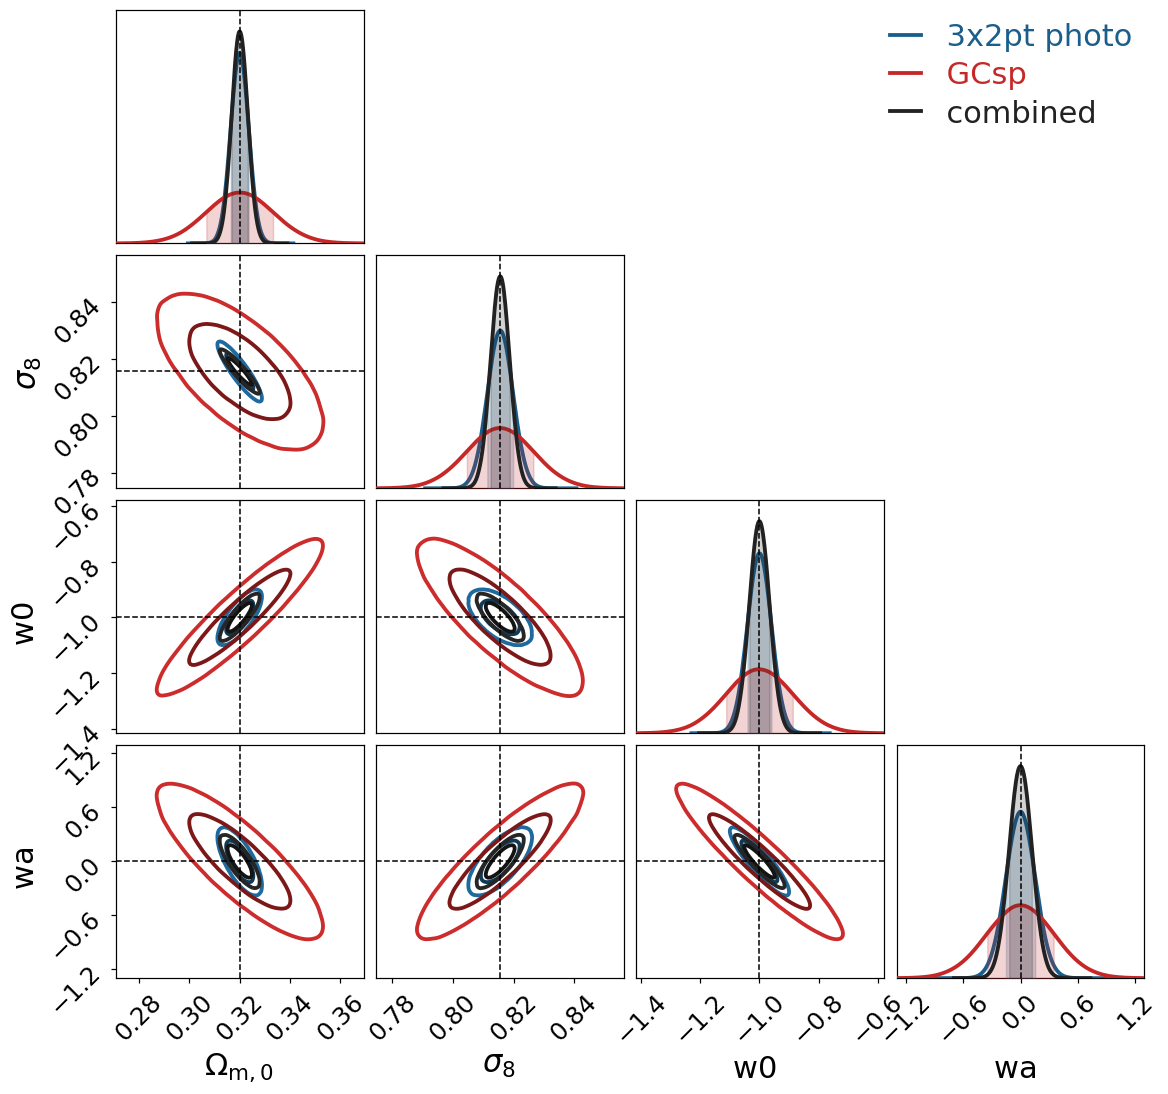

In [22]:
fig = fco.make_triangle_plot(
    fishers=[photo, spectro, combined],
    fisher_labels=['3x2pt photo', 'GCsp', 'combined'],
    params=['Omegam', 'sigma8', 'w0', 'wa'],
    colors=['#1B5E8C', '#C62828', '#222222'],
    truth_values=photo.get_param_names_fiducial_dict(),
    savefile=str(OUTPUT / 'probe_complementarity.png'),
)
plt.show()

Read the figure panel by panel.

* In the $(w_0,w_a)$ panel alone, the photometric and spectroscopic ellipses are **almost parallel**, so the gain there does not come from "crossing" ellipses.
* The combined (black) contour is nevertheless smaller than either: the probes constrain the *other* parameters differently ($\Omega_m$ and $\sigma_8$ are much better measured by the photometric probe; compare the $(\sigma_8,w_0)$ and $(\Omega_m,w_a)$ panels), and after marginalisation this tightens $(w_0,w_a)$ too.
* The figures of merit above are not additive (they are square roots of determinants), but note that the combined FoM exceeds the sum of the two.

Which probe constrains which parameter is discussed in Euclid Collaboration 2405.06047, Fig. 13.

### 3.2 Marginalising is not fixing: see it in the plot
Same photometric matrix, nuisance parameters **fixed** (`reshuffle`) versus **marginalised**: the first ellipse is the optimistic one.

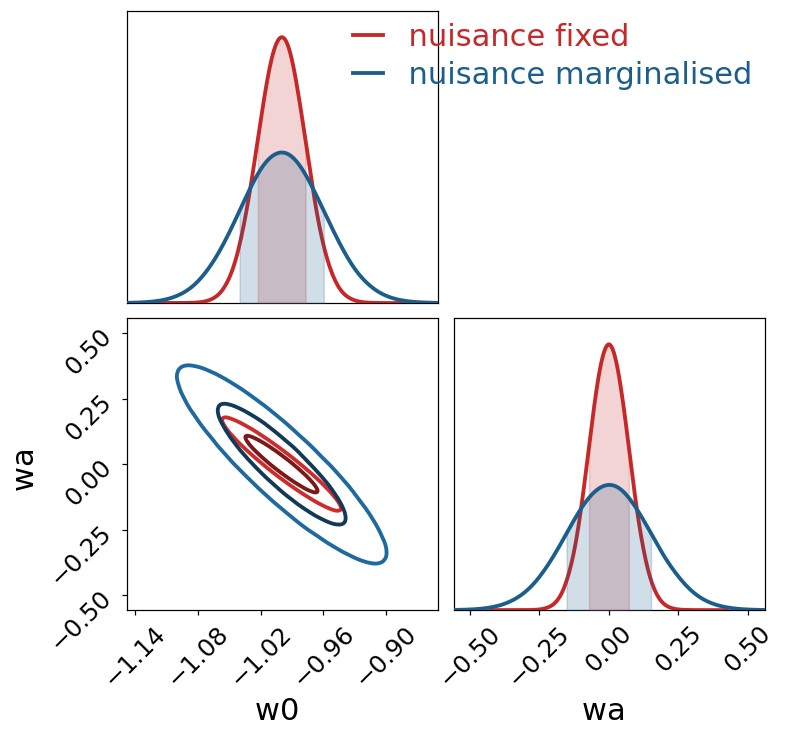

In [23]:
fig = fco.make_triangle_plot(
    fishers=[photo_fixed, photo_marg],
    fisher_labels=['nuisance fixed', 'nuisance marginalised'],
    params=['w0', 'wa'],
    colors=['#C62828', '#1B5E8C'],
)
plt.show()

### 3.3 Add a prior before inverting
An independent Gaussian prior on $h$ with width 0.01 contributes $F_{hh}^{\rm prior}=1/0.01^2$. This is an **illustrative scalar prior**, not a Planck likelihood. A real CMB prior is correlated and must use matching parameters and fiducials. We build a $1\times1$ `fisher_matrix` and use `+` again: the name `h` does the matching.

In [24]:
prior = fm.fisher_matrix(fisher_matrix=np.array([[1 / .01**2]]), param_names=['h'],
                         param_names_latex=['h'], fiducial=np.array([.67]), name='illustrative h prior')
with_prior = photo + prior
with_prior.name = 'photo pess + h prior'

def fom_of(f):
    return np.sqrt(np.linalg.det(ops.marginalise(f, ['w0', 'wa'], update_names=False).get_fisher_matrix()))
print('FoM without / with prior:', round(fom_of(photo), 1), round(fom_of(with_prior), 1))
assert fom_of(with_prior) >= fom_of(photo)

FoM without / with prior: 391.2 509.4


## 4. Baseline-model validation: archived high-precision runs
Load the local October 2026 CAMB/CLASS reruns with the 2023 baseline fiducial. These are **archived reruns**, not the published matrices themselves. Compare the errors with the published rounded values (2303.09451, Table 8); inspect the bundled `_specs.json` before interpreting differences.


In [25]:
archive = {f'{p}_{c}': fm.fisher_matrix(file_name=str(DATA / 'baseline' / f'{p}_{c}.txt'))
           for p in ['photo', 'spectro'] for c in ['camb', 'class']}
names = ['Omegab', 'h', 'ns', 'sigma8', 'Omegam', 'w0', 'wa']
def sigmas(f, names):
    reduced = ops.marginalise(f, names, update_names=False)
    return np.sqrt(np.diag(reduced.get_fisher_inverse()))
table = pd.DataFrame({key: sigmas(value, names) for key, value in archive.items()}, index=names)
table['paper_photo_CF'] = [.0027, .020, .010, .0041, .0036, .043, .17]
table['paper_photo_MCMC'] = [.0026, .021, .011, .0044, .0038, .045, .18]
table['photo_CAMB_CLASS_percent'] = 100*(table.photo_camb/table.photo_class - 1)
display(table)
table.to_csv(OUTPUT / 'baseline_comparison.csv')


,photo_camb,photo_class,spectro_camb,spectro_class,paper_photo_CF,paper_photo_MCMC,photo_CAMB_CLASS_percent
Omegab,0.002634,0.002654,0.002406,0.002414,0.0027,0.0026,-0.758221
h,0.020389,0.020456,0.020044,0.020050,0.0200,0.0210,-0.325467
ns,0.010212,0.010198,0.014193,0.014191,0.0100,0.0110,0.141609
sigma8,0.004085,0.004085,0.015422,0.015451,0.0041,0.0044,0.009878
Omegam,0.003553,0.003553,0.016053,0.016078,0.0036,0.0038,0.018233
w0,0.042511,0.042506,0.137025,0.137303,0.0430,0.0450,0.011201
wa,0.173568,0.173462,0.408443,0.409393,0.1700,0.1800,0.061267


### A real MontePython posterior
The bundled samples are from `w0wa_photo_pess`: seven cosmological parameters plus marginalised nuisances. Multiplicity weights are preserved; the first 30% of stored rows of each chain were discarded. This is a pedagogical overlay with the modern rerun, not a fresh convergence certification. The published matched-pipeline comparison is shown in the slides.


Removed no burn in


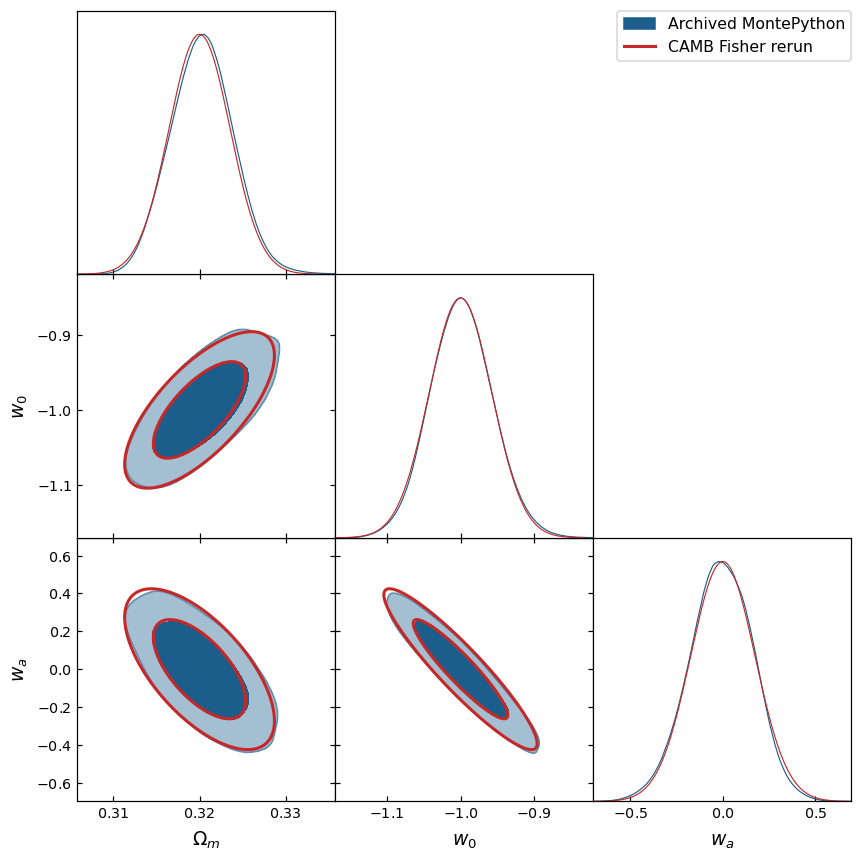

In [26]:
from getdist import MCSamples, plots
from getdist.gaussian_mixtures import GaussianND
stored = np.load(DATA / 'baseline/montepython_samples.npz')
a = stored['samples']
samples = MCSamples(samples=a[:, 2:], weights=a[:, 0], loglikes=a[:, 1],
    names=names, labels=[r'\Omega_b', 'h', 'n_s', r'\sigma_8', r'\Omega_m', 'w_0', 'w_a'],
    settings={'ignore_rows': 0})
f = ops.marginalise(archive['photo_camb'], names, update_names=False)
gaussian = GaussianND(f.get_param_fiducial(), f.get_fisher_inverse(), names=names)
g = plots.get_subplot_plotter(width_inch=8)
g.triangle_plot([samples, gaussian], ['Omegam', 'w0', 'wa'],
                filled=[True, False], legend_labels=['Archived MontePython', 'CAMB Fisher rerun'],
                colors=['#1B5E8C', '#C62828'], contour_colors=['#1B5E8C', '#C62828'], lws=[1.5, 2.0])
g.export(str(OUTPUT / 'baseline_montepython.png'))
plt.show()


## 5. Neutrinos: forecast errors versus a physical boundary
Load the 2024 **seven-parameter** $\Lambda$CDM+$M_\nu+N_{\rm eff}$ photometric pessimistic Fisher. The physical $M_\nu>0$ prior is not Gaussian and cannot be represented by simply adding a Fisher matrix.

The available local neutrino MCMC folder floats **nine** cosmological parameters (including $w_0,w_a$), unlike this validation case. We therefore show the **published matched-case MCMC comparison**, rather than overlaying an incompatible chain. Do not reproduce the final MCMC sensitivities (56/23/16 meV) using an unrestricted Gaussian ellipse.


['Omegam', 'Omegab', 'h', 'ns', 'sigma8', 'mnu', 'Neff', 'b1', 'b2', 'b3', 'b4', 'b5', 'b6', 'b7', 'b8', 'b9', 'b10', 'AIA', 'etaIA']


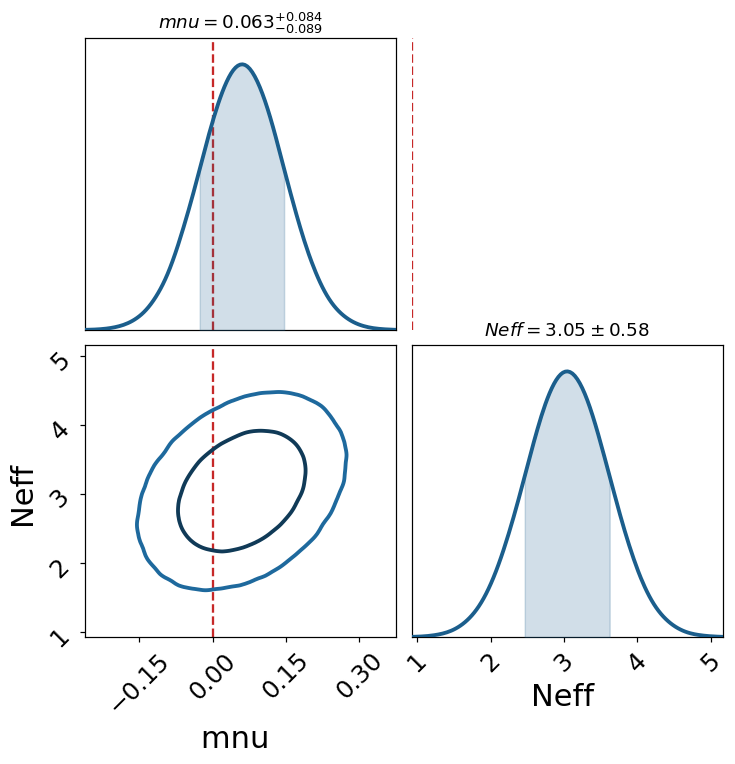

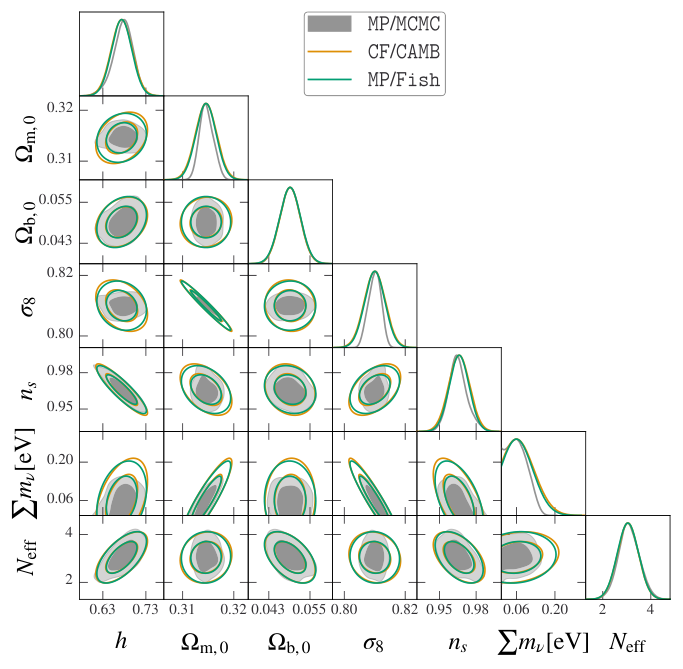

Credit: Euclid Collaboration, arXiv:2405.06047v1, Fig. 10 (photometric panel).


In [27]:
nu = fm.fisher_matrix(file_name=str(DATA / 'neutrino/cfp_camb.txt'))
print(nu.get_param_names())
fig = fco.make_triangle_plot(fishers=[nu], fisher_labels=['CAMB Fisher; 7 cosmological parameters'],
                             params=['mnu', 'Neff'], colors=['#1B5E8C'])
for ax in fig.axes:
    ax.axvline(0, color='#C62828', ls='--')   # physical boundary M_nu = 0
plt.show()
from IPython.display import Image, display
display(Image(filename=str(ROOT / 'data/figs/day2_neutrino.png'), width=700))
print('Credit: Euclid Collaboration, arXiv:2405.06047v1, Fig. 10 (photometric panel).')

## 6. Instructor's background Nautilus job
Optional: run the sampler yourself following `docs/nautilus.md`. It samples $(\Omega_m,\sigma_8,h)$ with fixed nuisance parameters. Nautilus is an importance nested sampler, not a Metropolis chain. Its weighted ESS has a different interpretation from MCMC autocorrelation ESS.

The cell below uses `LECTURE_NAUTILUS_DIR` if set; otherwise it shows the bundled local rehearsal. It always reads the job's own **conditional** reference Fisher. Use the job's metadata to check parameter names, priors and runtime.


{'free_params': ['Omegam', 'sigma8', 'h'], 'reference_kind': 'conditional', 'elapsed_seconds': 408.799973487854, 'effective_sample_size': 1195.855059306542}
Removed no burn in


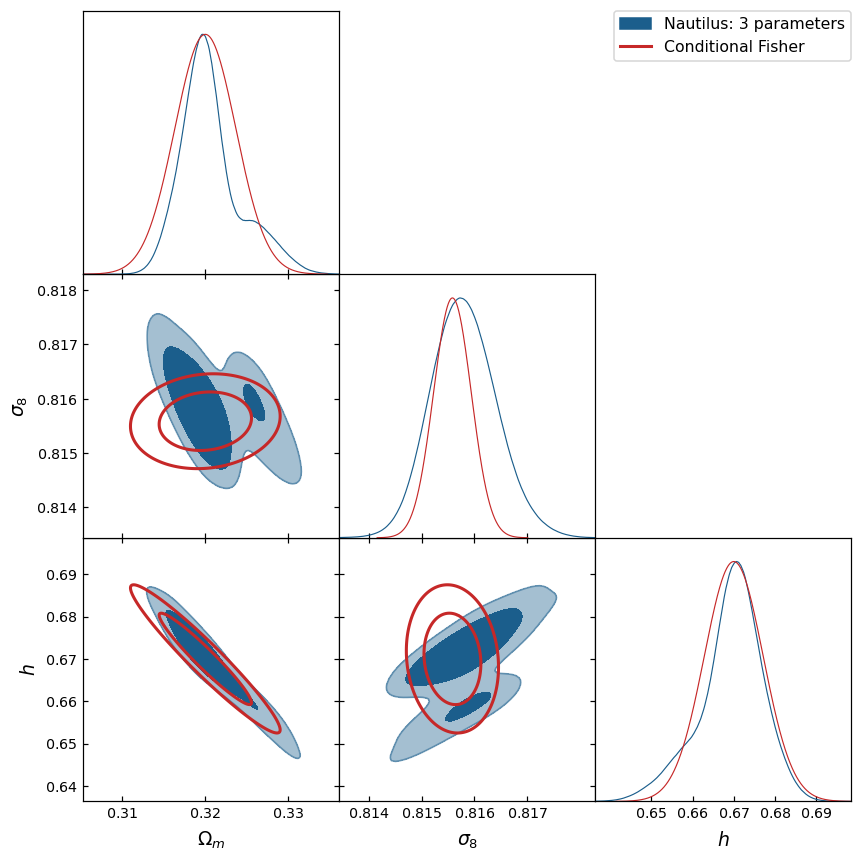

posterior std  (Nautilus): {'Omegam': 0.00372, 'sigma8': 0.00061, 'h': 0.00784}
posterior std  (Fisher)  : {'Omegam': 0.00368, 'sigma8': 0.00036, 'h': 0.00715}
corr(Om,s8), corr(s8,h) Nautilus: -0.51 0.59


In [28]:
run = Path(os.environ.get('LECTURE_NAUTILUS_DIR', str(DATA / 'nautilus/gcsp'))).expanduser()
meta = json.loads((run / 'case_metadata.json').read_text())
print({key: meta[key] for key in ['free_params', 'reference_kind', 'elapsed_seconds', 'effective_sample_size']})
chain = pd.read_csv(run / Path(meta['chain']).name)
reference = fm.fisher_matrix(file_name=str(run / Path(meta['fisher_reference']).name))
params = meta['sampled_parameters']
assert meta['reference_kind'] == 'conditional'
post = MCSamples(samples=chain[params].to_numpy(), weights=chain['weight'].to_numpy(),
                 names=params, labels=[r'\Omega_m', r'\sigma_8', 'h'])
ref = ops.reshuffle(reference, params, update_names=False)
normal = GaussianND(ref.get_param_fiducial(), ref.get_fisher_inverse(), names=params)
g = plots.get_subplot_plotter(width_inch=8)
g.triangle_plot([post, normal], params, filled=[True, False],
                legend_labels=['Nautilus: 3 parameters', 'Conditional Fisher'],
                colors=['#1B5E8C', '#C62828'], contour_colors=['#1B5E8C', '#C62828'], lws=[1.5, 2.0])
g.export(str(OUTPUT / 'nautilus_vs_fisher.png'))
plt.show()
sd = lambda c: np.sqrt(np.diag(c))
print('posterior std  (Nautilus):', dict(zip(params, np.round(sd(post.cov(params)), 5))))
print('posterior std  (Fisher)  :', dict(zip(params, np.round(sd(ref.get_fisher_inverse()), 5))))
print('corr(Om,s8), corr(s8,h) Nautilus:', np.round(post.corr(params)[0, 1], 2), np.round(post.corr(params)[1, 2], 2))

**Read this plot critically.** $\Omega_m$ and $h$ (and their degeneracy) agree between the sampler and the Fisher matrix. The $\sigma_8$ directions do **not**: the sampled posterior is wider in $\sigma_8$ and more correlated with $\Omega_m$ and $h$. We checked that this is not a sampler failure: a finite-difference Hessian of the very same `loglike` has cross terms $F_{\sigma_8 h}$ of opposite sign and much larger size than the first-derivative Fisher matrix. So the Fisher matrix and the likelihood differ in how the $\sigma_8$/bias-amplitude coupling is treated in this symbolic set-up, plus some emulator jitter. This is a good example for the class of why a Fisher forecast must be validated against the likelihood it is meant to approximate (as 2303.09451 does) -- and an item to follow up before quoting this case anywhere.

In [29]:
(OUTPUT / 'cfp_timings.json').write_text(json.dumps(timings, indent=2))


127

## Exercises
1. Predict what happens to the $w_0$–$w_a$ area when increasing $\ell_{\max}$. Compare `photo` and `photo_opt` (the `fom` series of §3). Why can modelling errors invalidate this statistical gain?
2. Change the illustrative $h$ prior to width 0.02. Does the FoM lie between the uninformative and 0.01-prior results?
3. Compare `ops.reshuffle` and `ops.marginalise` on the GCsp matrix. Which one is the right reference for the three-parameter Nautilus run? Then explain why $\sigma_8$ still disagrees (hint: finite-difference Hessian of `like.loglike`).
4. Optional workstation exercise: repeat a Fisher with half/double the derivative step, then replace symbolic by a matched high-precision CAMB profile. Compare *derivatives and marginalised errors*, not only $P(k)$.

**Answer scaffold:** a tighter independent prior cannot increase the Gaussian marginal covariance; a larger scale range adds information only under the assumed theory/covariance; fixed nuisance sampling requires the conditional Fisher. For the neutrino paper also match the tracer ($P_{cb}$ versus $P_m$), nonlinear model, neutrino convention, and physical priors.
